# MODELING BASELINE

<h3>Cell 0 - Import & Load Data</h3>
<p>
Pada cell ini, kami melakukan import library inti (pandas/numpy/matplotlib + scikit-learn) dan memuat dataset hasil labeling dari file <code>sparc_labeled.csv</code> yang berada satu folder dengan notebook. Tujuannya memastikan pipeline modeling berjalan dari dataset yang sudah memiliki target <code>label_repeat_next</code>.
</p>
<p>
Output awal seperti <code>Shape</code> dan preview baris digunakan untuk sanity check bahwa file yang dipakai sudah benar (bukan CSV mentah) dan kolom-kolom penting tersedia.
</p>

In [10]:
# Cell 0 — Import & Load Data
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

labeled_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
print("Labeled CSV path:", labeled_path)

df = pd.read_csv(labeled_path)
print("Shape:", df.shape)
df.head()

Labeled CSV path: c:\Patrick\coding\save later\sparc\sparc_labeled.csv
Shape: (319978, 34)


C:\Users\timot\AppData\Local\Temp\ipykernel_10688\1564193850.py:24: DtypeWarning: Columns (3,19,23,24,25,26,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(labeled_path)


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,...,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer,mohon_year,mohon_month,mohon_dow,mohon_quarter
0,cust-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03,...,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02,2019.0,1.0,2.0,1.0
1,cust-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27,...,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02,2019.0,1.0,2.0,1.0
2,cust-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-04-01,...,NaN,NaN,2019-01-02,6471-6400,1.0,2020-08-25,2019.0,1.0,2.0,1.0
3,cust-164422,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1997-06-26,...,NaN,NaN,2019-01-02,6471-6400,1.0,2022-05-12,2019.0,1.0,2.0,1.0
4,cust-155472,Baru Ulu,Balikpapan Barat,76133,2.0,11160.0,1,2,1,1996-12-07,...,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02,2019.0,1.0,2.0,1.0


<h3>Cell 1 - Casting Tanggal & Filter Data Berlabel</h3>
<p>
Pada cell ini, kami memastikan kolom <code>tgl mohon</code> bertipe datetime (karena dipakai untuk split berbasis waktu). Setelah itu, kami memfilter hanya baris yang memiliki target <code>label_repeat_next</code> (tidak NaN).
</p>
<p>
Alasan filtering: baris tanpa label umumnya disebabkan <code>tgl mohon</code> kosong sehingga transaksi tersebut tidak dapat diurutkan dalam waktu, sehingga target time-aware tidak bisa dibentuk secara valid. Dengan demikian, dataset untuk modeling menjadi subset yang “well-defined” untuk evaluasi.
</p>

In [11]:
# Cell 1 — Cast tipe tanggal + filter data berlabel

if "label_repeat_next" not in df.columns:
    raise ValueError("Kolom label_repeat_next tidak ditemukan. Pastikan labeling sudah disave ke sparc_labeled.csv")

if "tgl mohon" in df.columns:
    df["tgl mohon"] = pd.to_datetime(df["tgl mohon"], errors="coerce")
else:
    raise ValueError("Kolom 'tgl mohon' tidak ditemukan. Kita butuh ini untuk time-based split.")

# pakai hanya baris yang punya label (drop NaN)
df_model = df[df["label_repeat_next"].notna()].copy()
df_model["label_repeat_next"] = df_model["label_repeat_next"].astype(int)

print("Rows total:", df.shape[0])
print("Rows berlabel untuk modeling:", df_model.shape[0])
print("Repeat-next rate:", round(df_model["label_repeat_next"].mean() * 100, 2), "%")

print("tgl mohon NaT in df_model:", int(df_model["tgl mohon"].isna().sum()))

Rows total: 319978
Rows berlabel untuk modeling: 222314
Repeat-next rate: 12.5 %
tgl mohon NaT in df_model: 0


<h3>Cell 2 - Time-based Train/Test Split</h3>
<p>
Cell ini melakukan pemisahan data train dan test secara time-based: 80% tanggal paling awal untuk train dan 20% tanggal paling akhir untuk test. Pendekatan ini dibuat agar evaluasi lebih realistis (melatih dari histori dan menguji pada periode masa depan), sekaligus menghindari leakage.
</p>
<p>
Perbedaan repeat rate train vs test dapat terjadi (label shift) karena definisi label “ada transaksi setelah tanggal ini” secara alami akan menurun pada periode mendekati ujung data (right-censoring). Oleh karena itu, metrik threshold-independent seperti ROC-AUC dan PR-AUC diprioritaskan.
</p>

In [12]:
# Cell 2 — Time-based split
df_model = df_model.sort_values("tgl mohon").reset_index(drop=True)

# split: 80% awal untuk train, 20% akhir untuk test
split_idx = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_idx].copy()
test_df  = df_model.iloc[split_idx:].copy()

print("Train period:", train_df["tgl mohon"].min(), "->", train_df["tgl mohon"].max(), "| n:", train_df.shape[0])
print("Test period :", test_df["tgl mohon"].min(),  "->", test_df["tgl mohon"].max(),  "| n:", test_df.shape[0])

y_train = train_df["label_repeat_next"].values
y_test  = test_df["label_repeat_next"].values

print("Train repeat rate:", round(y_train.mean() * 100, 2), "%")
print("Test repeat rate :", round(y_test.mean() * 100, 2), "%")

Train period: 2019-01-02 00:00:00 -> 2025-01-11 00:00:00 | n: 177851
Test period : 2025-01-11 00:00:00 -> 2025-12-31 00:00:00 | n: 44463
Train repeat rate: 14.71 %
Test repeat rate : 3.69 %


<h3>Cell 3 - Feature Selection</h3>
<p>
Cell ini adalah revisi penting dari versi baseline awal. Pada percobaan sebelumnya, kolom tanggal mentah
(<code>tgl mohon</code>, <code>tgl cetak</code>, <code>tgl lahir</code>) masih ikut menjadi fitur dan berisiko diperlakukan sebagai kategori oleh
OneHotEncoder, yang dapat membuat model kurang stabil.
</p>
<p>
Pada versi terbaru, tahap <i>feature engineering</i> untuk waktu sudah dilakukan lebih awal pada tahap
<b>Preprocessing & Feature Engineering</b> (sebelum data disimpan ke CSV). Karena itu, di baseline modeling ini kami hanya melakukan
<b>seleksi fitur</b> dengan cara:
</p>
<ul>
  <li>menghapus kolom datetime mentah agar tidak ikut masuk ke encoder,</li>
  <li>menghapus kolom helper/leakage dari proses labeling (mis. <code>max_tgl_mohon_customer</code>),</li>
  <li>menghapus kolom ID seperti <code>customer id</code> agar model baseline tidak “menghafal” identitas.</li>
</ul>
<p>
Fitur waktu turunan yang aman dan informatif (<code>mohon_year</code>, <code>mohon_month</code>, <code>mohon_dow</code>, <code>mohon_quarter</code>)
sudah tersedia di dataset hasil preprocessing, sehingga tetap digunakan sebagai fitur tanpa perlu dibuat ulang di sini.
</p>
<p>
Hasil akhir cell ini adalah <code>X_train_raw</code> dan <code>X_test_raw</code> yang berisi fitur siap diproses,
tanpa kolom leakage/helper serta tanpa kolom datetime mentah.
</p>

In [13]:
# Cell 3 Feature selection

drop_cols = [
    "label_repeat_next",
    "max_tgl_mohon_customer",
    "customer id",
]

# drop kolom datetime mentah supaya tidak ikut OHE
datetime_raw_cols = [c for c in ["tgl mohon", "tgl cetak", "tgl lahir"] if c in train_df.columns]

drop_cols = [c for c in drop_cols if c in train_df.columns] + datetime_raw_cols

X_train_raw = train_df.drop(columns=drop_cols)
X_test_raw = test_df.drop(columns=drop_cols)

print("Dropped:", drop_cols)
print("X_train shape:", X_train_raw.shape)
print("X_test shape :", X_test_raw.shape)

# QC kecil: pastikan fitur waktu memang ada
need_time = ["mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"]
print("Time features exist:", {c: (c in X_train_raw.columns) for c in need_time})

Dropped: ['label_repeat_next', 'max_tgl_mohon_customer', 'customer id', 'tgl mohon', 'tgl cetak', 'tgl lahir']
X_train shape: (177851, 28)
X_test shape : (44463, 28)
Time features exist: {'mohon_year': True, 'mohon_month': True, 'mohon_dow': True, 'mohon_quarter': True}


<h3>Cell 4 - Tentukan Fitur Numerik vs Kategorikal</h3>
<p>
Cell ini menyiapkan pemisahan fitur numerik dan kategorikal. Kolom numerik (mis. <code>dp aktual</code>, <code>cicilan</code>, <code>otr</code>, <code>umur</code>, dll) di-cast menjadi numeric dengan <code>errors="coerce"</code> agar nilai anomali berubah menjadi NaN dan bisa diimputasi.
</p>
<p>
Revisi utama di sini adalah normalisasi tipe pada kolom kategorikal: seluruh nilai dikonversi menjadi string yang bersih (strip whitespace), sementara missing tetap NaN. Ini menghindari error encoder terkait tipe campuran (mis. integer bercampur string) dan memastikan OneHotEncoder menerima input yang konsisten.
</p>

In [14]:
# Cell 4 - Tentukan num/cat + clean kategori seragam string

numeric_candidates = [
    "dp aktual", "cicilan", "otr", "umur", "tahun rakit", "tenor",
    "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"
]
num_cols = [c for c in numeric_candidates if c in X_train_raw.columns]

for c in num_cols:
    X_train_raw[c] = pd.to_numeric(X_train_raw[c], errors="coerce")
    X_test_raw[c] = pd.to_numeric(X_test_raw[c], errors="coerce")

cat_cols = [c for c in X_train_raw.columns if c not in num_cols]

def to_clean_string(v):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return np.nan
    if isinstance(v, str):
        s = v.strip()
        return np.nan if s == "" else s
    return str(v).strip()

for c in cat_cols:
    X_train_raw[c] = X_train_raw[c].map(to_clean_string).astype(object)
    X_test_raw[c] = X_test_raw[c].map(to_clean_string).astype(object)

print("Num cols:", num_cols)
print("Cat cols count:", len(cat_cols))

Num cols: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit', 'tenor', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']
Cat cols count: 18


<h3>Cell 5 - Preprocessing Pipeline & Dua Baseline Model</h3>
<p>
Cell ini membangun pipeline preprocessing menggunakan <code>ColumnTransformer</code>:
</p>
<ul>
  <li>
    <b>Numerik:</b> imputasi median + <code>StandardScaler</code> untuk menstabilkan logistic regression (membuat koefisien lebih interpretable dan optimisasi lebih baik).
  </li>
  <li>
    <b>Kategorikal:</b> imputasi konstanta <code>"MISSING"</code> + OneHotEncoder dengan <code>min_frequency=50</code> agar kategori yang sangat jarang tidak meledakkan dimensi fitur.
  </li>
</ul>
<p>
Pada baseline modeling, kami melatih dua varian logistic regression:
</p>
<ul>
  <li><b>Vanilla:</b> tanpa <code>class_weight</code>, sebagai baseline standar.</li>
  <li><b>Balanced:</b> dengan <code>class_weight="balanced"</code>, untuk membandingkan trade-off recall vs precision pada data tidak seimbang.</li>
</ul>
<p>
Perbandingan dua model ini membuat hasil lebih kuat untuk laporan: baseline tidak hanya satu angka, tetapi menunjukkan efek strategi penanganan imbalance.
</p>

In [15]:
# Cell 5 - Preprocess + 2 Baseline LR (vanilla & balanced)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()) 
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop"
)

lr_vanilla = LogisticRegression(
    max_iter=400,
    random_state=RANDOM_SEED
)

lr_balanced = LogisticRegression(
    max_iter=400,
    random_state=RANDOM_SEED,
    class_weight="balanced"
)

baseline_vanilla = Pipeline(steps=[("preprocess", preprocess), ("model", lr_vanilla)])
baseline_balanced = Pipeline(steps=[("preprocess", preprocess), ("model", lr_balanced)])

baseline_vanilla, baseline_balanced

(Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   ['dp aktual', 'cicilan',
                                                    'otr', 'umur', 'tahun rakit',
                                                    'tenor', 'mohon_year',
                                                    'mohon_month', 'mohon_dow',
                                                    'mohon_quarter']),
                                                  ('cat',
                                                   Pipeline(steps=[('imputer',
                                        

<h3>Cell 6 - Training & Probabilitas Prediksi</h3>
<p>
Cell ini melakukan training untuk kedua baseline model dan menampilkan ringkasan distribusi probabilitas prediksi (min/mean/max). Ringkasan ini berfungsi sebagai quality check:
</p>
<ul>
  <li>Jika probabilitas terlalu sempit dan berkumpul di ~0.5, model biasanya tidak belajar signal (atau fitur tidak benar).</li>
  <li>Jika probabilitas lebih tersebar, model berpotensi menangkap pola yang relevan.</li>
</ul>
<p>
Pada revisi ini, distribusi probabilitas menjadi lebih masuk akal dibanding versi awal yang hampir konstan, yang menunjukkan perbaikan feature handling dan preprocessing berhasil.
</p>

In [16]:
# Cell 6— Train + proba summary

baseline_vanilla.fit(X_train_raw, y_train)
proba_vanilla = baseline_vanilla.predict_proba(X_test_raw)[:, 1]

baseline_balanced.fit(X_train_raw, y_train)
proba_balanced = baseline_balanced.predict_proba(X_test_raw)[:, 1]

print("Vanilla proba min/mean/max:",
      float(np.min(proba_vanilla)), float(np.mean(proba_vanilla)), float(np.max(proba_vanilla)))
print("Balanced proba min/mean/max:",
      float(np.min(proba_balanced)), float(np.mean(proba_balanced)), float(np.max(proba_balanced)))

Vanilla proba min/mean/max: 0.0020087595117244256 0.06036661837860437 0.8398542453196749
Balanced proba min/mean/max: 0.013205204640539618 0.21946898820645422 0.9651670541389681


<h3>Cell 7 — Evaluasi (ROC-AUC, PR-AUC, F1, Confusion Matrix) + ROC/PR Curve </h3>
<p>
Cell ini mengevaluasi kedua model baseline menggunakan metrik yang sesuai untuk kasus klasifikasi tidak seimbang:
</p>
<ul>
  <li><b>ROC-AUC</b> sebagai metrik utama threshold-independent.</li>
  <li><b>PR-AUC (Average Precision)</b> untuk menilai performa pada kelas positif yang minoritas.</li>
  <li><b>F1 @ threshold 0.5</b> dan <b>Confusion Matrix</b> untuk interpretasi operasional.</li>
</ul>
<p>
Perbandingan yang umum terlihat:
</p>
<ul>
  <li><b>Vanilla</b> cenderung lebih konservatif: precision lebih tinggi tetapi recall lebih rendah.</li>
  <li><b>Balanced</b> cenderung lebih agresif: recall naik tetapi precision turun.</li>
</ul>
<p>
Plot ROC dan PR curve membantu memvisualisasikan performa secara menyeluruh tanpa bergantung pada satu threshold.
</p>


Baseline LR (Vanilla)
ROC-AUC: 0.793
PR-AUC : 0.2951
F1@0.5 : 0.2711
Confusion Matrix @0.5:
 [[42658   164]
 [ 1358   283]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9691    0.9962    0.9825     42822
           1     0.6331    0.1725    0.2711      1641

    accuracy                         0.9658     44463
   macro avg     0.8011    0.5843    0.6268     44463
weighted avg     0.9567    0.9658    0.9562     44463



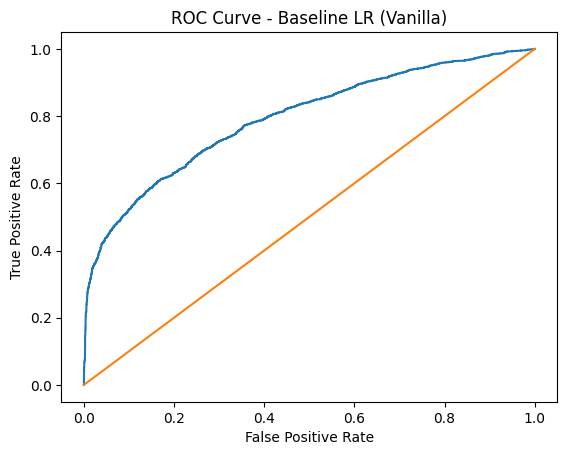

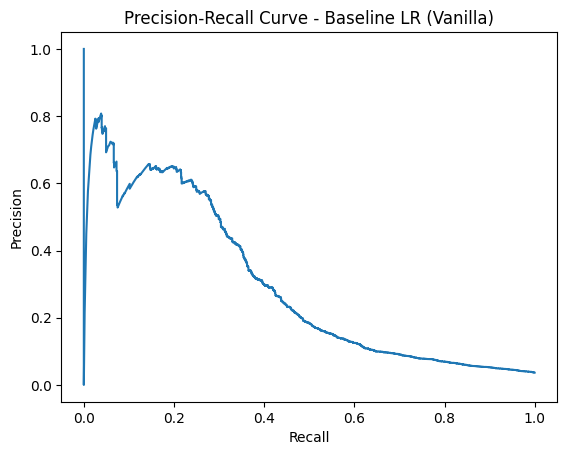


Baseline LR (Balanced)
ROC-AUC: 0.7922
PR-AUC : 0.288
F1@0.5 : 0.3565
Confusion Matrix @0.5:
 [[41688  1134]
 [ 1039   602]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9757    0.9735    0.9746     42822
           1     0.3468    0.3668    0.3565      1641

    accuracy                         0.9511     44463
   macro avg     0.6612    0.6702    0.6656     44463
weighted avg     0.9525    0.9511    0.9518     44463



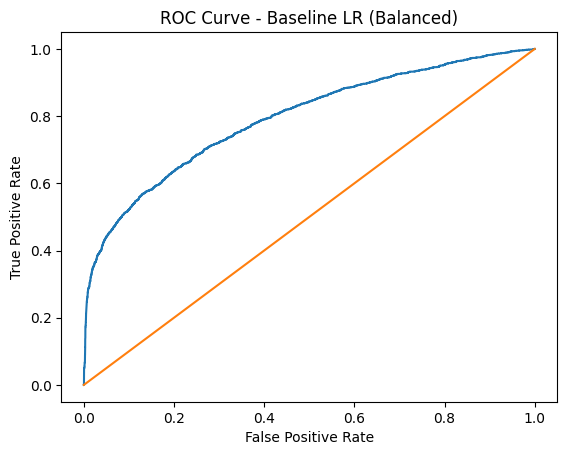

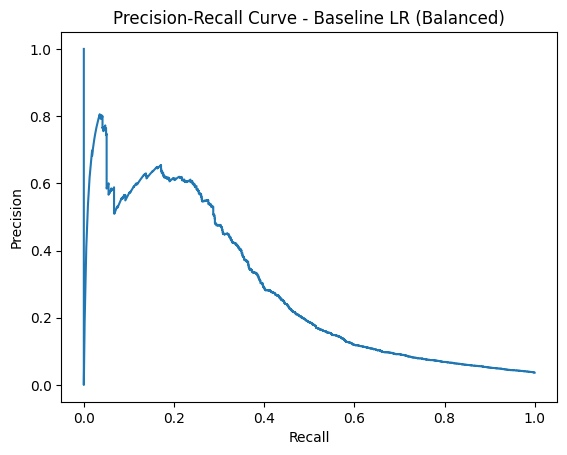

In [17]:
# Cell 7 — Evaluation helper + plot
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

def evaluate_probs(y_true, y_proba, title="Model"):
    roc_auc = roc_auc_score(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)

    # threshold 0.5
    y_pred_05 = (y_proba >= 0.5).astype(int)
    f1_05 = f1_score(y_true, y_pred_05)

    print("\n==============================")
    print(title)
    print("ROC-AUC:", round(roc_auc, 4))
    print("PR-AUC :", round(pr_auc, 4))
    print("F1@0.5 :", round(f1_05, 4))
    print("Confusion Matrix @0.5:\n", confusion_matrix(y_true, y_pred_05))
    print("\nReport @0.5:\n", classification_report(y_true, y_pred_05, digits=4))

    # ROC
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    plt.figure()
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1])
    plt.title(f"ROC Curve - {title}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.show()

    # PR
    prec, rec, _ = precision_recall_curve(y_true, y_proba)
    plt.figure()
    plt.plot(rec, prec)
    plt.title(f"Precision-Recall Curve - {title}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.show()

evaluate_probs(y_test, proba_vanilla, "Baseline LR (Vanilla)")
evaluate_probs(y_test, proba_balanced, "Baseline LR (Balanced)")

<h3>Cell 8 - Interpretasi Model: Top Coefficients</h3>
<p>
Cell ini mengekstrak nama fitur setelah preprocessing (numerik + hasil OneHotEncoder) lalu menggabungkannya dengan koefisien logistic regression untuk interpretasi.
</p>
<p>
Kami menampilkan:
</p>
<ul>
  <li><b>Top abs coefficients</b>: fitur yang paling berpengaruh secara magnitude.</li>
  <li><b>Top positif</b>: fitur yang meningkatkan peluang repeat.</li>
  <li><b>Top negatif</b>: fitur yang menurunkan peluang repeat.</li>
</ul>
<p>
Catatan penting: karena OneHotEncoder menggunakan <code>min_frequency</code>, kategori langka dapat digabung menjadi fitur seperti <code>..._infrequent_sklearn</code>. Ini adalah desain untuk menjaga dimensi fitur tetap terkontrol dan justru membuat baseline lebih stabil.
</p>
<p>
Output koefisien ini dapat dipakai sebagai bahan narasi laporan untuk menjelaskan fitur/segmen mana yang terkait dengan repeat order, dengan catatan bahwa koefisien logistic menunjukkan korelasi (bukan kausalitas).
</p>

In [18]:
# Cell 8 — Interpretasi Logistic Regression: top coefficients
import numpy as np
import pandas as pd

def get_feature_names_from_preprocess(preprocess, num_cols, cat_cols):
    feature_names = []

    feature_names.extend(num_cols)

    ohe = preprocess.named_transformers_["cat"].named_steps["onehot"]
    cat_feature_names = ohe.get_feature_names_out(cat_cols).tolist()
    feature_names.extend(cat_feature_names)

    return feature_names

def coef_table(model_pipeline, num_cols, cat_cols, top_k=20):
    pre = model_pipeline.named_steps["preprocess"]
    lr = model_pipeline.named_steps["model"]

    feature_names = get_feature_names_from_preprocess(pre, num_cols, cat_cols)
    coefs = lr.coef_.ravel()

    if len(feature_names) != len(coefs):
        print("WARNING: feature_names length != coef length",
              len(feature_names), len(coefs))

    df_coef = pd.DataFrame({
        "feature": feature_names[:len(coefs)],
        "coef": coefs[:len(feature_names)]
    })
    df_coef["abs_coef"] = df_coef["coef"].abs()
    df_coef = df_coef.sort_values("abs_coef", ascending=False)

    print(f"Top {top_k} fitur paling berpengaruh (abs coef):")
    display(df_coef.head(top_k)[["feature", "coef"]])

    print(f"Top {min(10, top_k)} coef positif (naikkan peluang repeat):")
    display(df_coef.sort_values("coef", ascending=False).head(min(10, top_k))[["feature", "coef"]])

    print(f"Top {min(10, top_k)} coef negatif (turunkan peluang repeat):")
    display(df_coef.sort_values("coef", ascending=True).head(min(10, top_k))[["feature", "coef"]])

    return df_coef


coef_df_vanilla = coef_table(baseline_vanilla, num_cols, cat_cols, top_k=25)

Top 25 fitur paling berpengaruh (abs coef):


,feature,coef
75,kelurahan_Bumi Harapan,2.668036
783,gender_N,1.281761
282,kelurahan_OLONG PINANG,-1.250372
229,kelurahan_MALINAU HULU,1.220822
505,kecamatan_BENGALON,1.107556
517,kecamatan_Barong Tongkok,1.056703
917,wilayah_infrequent_sklearn,-1.016612
782,gender_2,-0.906250
34,kelurahan_BENA BARU,-0.903944
334,kelurahan_SALO LOANG,-0.897805


Top 10 coef positif (naikkan peluang repeat):


,feature,coef
75,kelurahan_Bumi Harapan,2.668036
783,gender_N,1.281761
229,kelurahan_MALINAU HULU,1.220822
505,kecamatan_BENGALON,1.107556
517,kecamatan_Barong Tongkok,1.056703
274,kelurahan_NIPAH NIPAH,0.849533
67,kelurahan_Barong Tongkok,0.832675
745,kode dealer_13853.0,0.828389
57,kelurahan_BULUMINUNG,0.817828
362,kelurahan_SEMURUT,0.793302


Top 10 coef negatif (turunkan peluang repeat):


,feature,coef
282,kelurahan_OLONG PINANG,-1.250372
917,wilayah_infrequent_sklearn,-1.016612
782,gender_2,-0.906250
34,kelurahan_BENA BARU,-0.903944
334,kelurahan_SALO LOANG,-0.897805
781,gender_1,-0.869879
554,kecamatan_SAMARINDA ULU,-0.848202
1007,kode kota-provinsi_6474-6400,-0.842185
911,wilayah_6474,-0.842185
151,kelurahan_KARANG JATI,-0.833232
